# Exome Variant Analysis: Chromosome 17 (GRCh38)

**Sample:** HG003 (Genome in a Bottle, Ashkenazi trio father), Illumina NovaSeq exome (IDT capture)
**Goal:** Call, annotate and benchmark germline variants on chr17 using a standard GATK best-practices workflow.
**Tools:** fastp, FastQC/MultiQC, BWA, SAMtools, GATK4, mosdepth, bcftools (including `csq`)
**Pipeline:** QC and trimming → alignment → duplicate marking and BQSR → variant calling → filtering → gnomAD and functional annotation → GIAB benchmark

## 1. Environment setup
Installs the command-line tools and sets the project paths so the analysis is reproducible.
*Versions: BWA 0.7.19, SAMtools and bcftools 1.25, GATK 4.6.2.0, fastp 1.4.0, mosdepth 0.3.3.*


In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

✨🍰✨ Everything looks OK!


In [ ]:
%%bash
mamba install -y -q -c conda-forge -c bioconda \
    fastqc fastp multiqc bwa samtools bcftools htslib bedtools gatk4 mosdepth 2>&1 | tail -3

    - bin/markdown_py
warning  libmamba [jsonschema-4.26.0-pyhcf101f3_1] The following files were already present in the environment:
    - bin/jsonschema


In [ ]:
import os, sys, io, json, gzip, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

proj = os.path.expanduser('~/exome_project')
os.environ['PROJ'] = proj          # so %%bash cells can use $PROJ
os.environ['CHR'] = 'chr17'        # the chromosome we analyse
np.random.seed(0)

print("Python", sys.version.split()[0])
from importlib.metadata import version
for pkg in ['numpy', 'pandas', 'matplotlib']:
    print(f"{pkg:12s}", version(pkg))

Python 3.13.18
numpy        2.5.4
pandas       2.2.3
matplotlib   3.10.0


In [ ]:
# Check installed tool versions
%%bash
bwa 2>&1 | grep Version
samtools --version | head -1
bcftools --version | head -1
fastqc --version | head -1
multiqc --version | head -1
bedtools --version | head -1
fastp --version
echo "gatk:     $(gatk --version 2>/dev/null | grep 'Genome Analysis Toolkit')"
echo "mosdepth: $(mosdepth --version)"

Version: 0.7.19-r1273
samtools 1.25
bcftools 1.25
FastQC v0.13.0
multiqc, version 1.35
bedtools v2.31.1
fastp 1.4.0
gatk:     The Genome Analysis Toolkit (GATK) v4.6.2.0
mosdepth: mosdepth 0.3.3


## 2. Project structure and reference data
Creates the folder layout and downloads the chr17 reference (GRCh38), capture targets, known-variant resources, gnomAD frequencies and the GIAB truth set, so every step uses matching coordinates.
*Result: chr17 reference of 83.3 Mb; 11,933 merged capture regions covering 2.16 Mb.*

In [ ]:
%%bash
mkdir -p $PROJ/{raw_data,reference,qc,trimmed,alignment,variants,results}
cd $PROJ
echo "Project structure created:"
find . -type d | sort

Project structure created:
.
./alignment
./qc
./raw_data
./reference
./results
./trimmed
./variants


In [ ]:
#reference genome
%%bash
cd $PROJ/reference
wget -q https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/${CHR}.fa.gz
gunzip -f ${CHR}.fa.gz
samtools faidx ${CHR}.fa
gatk CreateSequenceDictionary -R ${CHR}.fa -O ${CHR}.dict 2>&1 | tail -1
ls -lh ${CHR}.*

0
-rw-r--r-- 1 root root 121 Nov 11 06:39 chr17.dict
-rw-r--r-- 1 root root 81M Jan 24  2014 chr17.fa
-rw-r--r-- 1 root root  23 Nov 11 06:38 chr17.fa.fai


In [ ]:
#capture targets (chr17 only)
%%bash
cd $PROJ/reference
wget -q https://storage.googleapis.com/deepvariant/exome-case-study-testdata/idt_capture_novogene.grch38.bed -O targets.all.bed
grep -P "^${CHR}\t" targets.all.bed | cut -f1-3 | sort -k2,2n | bedtools merge > targets.bed
echo "Target regions on $CHR: $(wc -l < targets.bed)"
head -3 targets.bed

Target regions on chr17: 11933
chr17	156219	156377
chr17	161414	161541
chr17	162080	162190


In [ ]:
%%bash
cd $PROJ/reference
BUNDLE=https://storage.googleapis.com/gcp-public-data--broad-references/hg38/v0

bcftools view -r $CHR $BUNDLE/Mills_and_1000G_gold_standard.indels.hg38.vcf.gz -Oz -o mills.vcf.gz 2>/dev/null
bcftools index -t -f mills.vcf.gz

bcftools view -r $CHR $BUNDLE/1000G_phase1.snps.high_confidence.hg38.vcf.gz -Oz -o 1000G_snps.vcf.gz 2>/dev/null
bcftools index -t -f 1000G_snps.vcf.gz

echo "mills:      $(bcftools view -H mills.vcf.gz | wc -l) variants"
echo "1000G SNPs: $(bcftools view -H 1000G_snps.vcf.gz | wc -l) variants"

mills:      36461 variants
1000G SNPs: 707176 variants


[W::bcf_hdr_check_sanity] SB should be declared as Number=4
[W::bcf_hdr_check_sanity] SB should be declared as Type=Integer
[W::bcf_hdr_check_sanity] SB should be declared as Number=4
[W::bcf_hdr_check_sanity] SB should be declared as Type=Integer


In [ ]:
#gnomAD frequencies and the GIAB answer key
%%bash
cd $PROJ/reference
GIAB=https://ftp-trace.ncbi.nlm.nih.gov/giab/ftp/release/AshkenazimTrio/HG003_NA24149_father/NISTv4.2.1/GRCh38

bcftools view -r $CHR https://storage.googleapis.com/gatk-best-practices/somatic-hg38/af-only-gnomad.hg38.vcf.gz -Oz -o gnomad.vcf.gz
bcftools index -t gnomad.vcf.gz

bcftools view -r $CHR $GIAB/HG003_GRCh38_1_22_v4.2.1_benchmark.vcf.gz -Oz -o truth.vcf.gz
bcftools index -t truth.vcf.gz

wget -q $GIAB/HG003_GRCh38_1_22_v4.2.1_benchmark_noinconsistent.bed -O - | grep -P "^${CHR}\t" > giab_confident.bed

echo "gnomAD: $(bcftools view -H gnomad.vcf.gz | wc -l) variants"
echo "Truth:  $(bcftools view -H truth.vcf.gz | wc -l) variants"
ls -lh

gnomAD: 7444506 variants
Truth:  108201 variants
total 218M
-rw-r--r-- 1 root root 2.1M Nov 11 06:39 1000G_phase1.snps.high_confidence.hg38.vcf.gz.tbi
-rw-r--r-- 1 root root  42M Nov 11 06:39 1000G_snps.vcf.gz
-rw-r--r-- 1 root root  56K Nov 11 06:39 1000G_snps.vcf.gz.tbi
-rw-r--r-- 1 root root 2.4M Nov 11 06:39 af-only-gnomad.hg38.vcf.gz.tbi
-rw-r--r-- 1 root root  121 Nov 11 06:39 chr17.dict
-rw-r--r-- 1 root root  81M Jan 24  2014 chr17.fa
-rw-r--r-- 1 root root   23 Nov 11 06:38 chr17.fa.fai
-rw-r--r-- 1 root root 555K Nov 11 06:39 giab_confident.bed
-rw-r--r-- 1 root root  78M Nov 11 06:39 gnomad.vcf.gz
-rw-r--r-- 1 root root  60K Nov 11 06:39 gnomad.vcf.gz.tbi
-rw-r--r-- 1 root root 1.6M Nov 11 06:39 HG003_GRCh38_1_22_v4.2.1_benchmark.vcf.gz.tbi
-rw-r--r-- 1 root root 1.5M Nov 11 06:39 Mills_and_1000G_gold_standard.indels.hg38.vcf.gz.tbi
-rw-r--r-- 1 root root 549K Nov 11 06:39 mills.vcf.gz
-rw-r--r-- 1 root root  42K Nov 11 06:39 mills.vcf.gz.tbi
-rw-r--r-- 1 root root 4.7M Nov 

## 3. Input reads
Extracts the chr17 read pairs from a public HG003 exome alignment and converts them back to FASTQ, giving a realistic but smaller dataset.
*Result: 2,387,574 read pairs (151 bp reads).*

In [ ]:
%%bash
cd $PROJ/raw_data
rm -f tmp.*.bam chr17*.bam *.bai      # remove leftovers from earlier runs

BAM=https://storage.googleapis.com/deepvariant/exome-case-study-testdata/HG003.novaseq.wes_idt.100x.dedup.bam

samtools view -b -o chr17.bam "$BAM" $CHR
samtools sort -n -o chr17.byname.bam chr17.bam
samtools fastq -1 sample_R1.fastq.gz -2 sample_R2.fastq.gz -s /dev/null chr17.byname.bam

rm -f chr17.bam chr17.byname.bam *.bai
ls -lh

total 345M
-rw-r--r-- 1 root root 170M Nov 11 06:42 sample_R1.fastq.gz
-rw-r--r-- 1 root root 175M Nov 11 06:42 sample_R2.fastq.gz


[bam_sort_core] merging from 2 files and 1 in-memory blocks...
[M::bam2fq_mainloop] discarded 17568 singletons
[M::bam2fq_mainloop] processed 4792716 reads


In [ ]:
%%bash
cd $PROJ/raw_data
echo "--- First read of R1 (4 lines) ---"
zcat sample_R1.fastq.gz | head -4
echo
echo "--- Target BED (first 5 regions) ---"
head -5 $PROJ/reference/targets.bed

--- First read of R1 (4 lines) ---
@A00744:48:HV33LDSXX:3:1101:1036:1658
CTTNGAAATAAATCACAGTTGTTCCCAGAGNTATTCAGGGTTAAANCCNAGAGCCTCCGAGNACAGGAAATNCACTCCCAGNGGTTTTCTACCTTATTAATCCATTGACCTCATCCNCAATGTGGCGCAGCTTGTAATAAGCATCAGTTGG
+
FFF#FF:F:FFFFFFFFFFFFFFFFFFFFF#FFFFFFFFFFFFFF#FF#FFFFFFFFFFFF#FFFFFFFFF#FFFFFFFFF#FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF#FF,FFFFFFFF:FF:FFFFFFFFFFFFFFFFFFF

--- Target BED (first 5 regions) ---
chr17	156219	156377
chr17	161414	161541
chr17	162080	162190
chr17	164129	164204
chr17	172536	172616


In [ ]:
def count_reads(path):
    with gzip.open(path, 'rt') as f:
        return sum(1 for _ in f) // 4

n1 = count_reads(proj + '/raw_data/sample_R1.fastq.gz')
n2 = count_reads(proj + '/raw_data/sample_R2.fastq.gz')
assert n1 == n2 and n1 > 0, "R1 and R2 have different (or zero) read counts - rerun the download cell"
print(f"Pairs OK: {n1:,} read pairs")

Pairs OK: 2,387,574 read pairs


## 4. Read quality control and trimming
FastQC and fastp check read quality and remove adapters and low-quality reads, so only reliable bases reach the aligner. MultiQC combines the reports.
*Result: 99.1% of reads kept; Q30 rose from 94.0% to 94.4%; 162,530 reads had adapters trimmed.*

In [ ]:
%%bash
cd $PROJ
fastqc -q -t 2 --outdir qc/ raw_data/sample_R1.fastq.gz raw_data/sample_R2.fastq.gz
ls qc/

sample_R1_fastqc.html
sample_R1_fastqc.zip
sample_R2_fastqc.html
sample_R2_fastqc.zip


In [ ]:
%%bash
cd $PROJ
fastp \
  -i raw_data/sample_R1.fastq.gz -I raw_data/sample_R2.fastq.gz \
  -o trimmed/sample_R1.trim.fastq.gz -O trimmed/sample_R2.trim.fastq.gz \
  --detect_adapter_for_pe \
  --length_required 36 \
  --thread 2 \
  --json qc/fastp.json --html qc/fastp.html 2>&1 | grep -A6 'Filtering result'

Filtering result:
reads passed filter: 4734224
reads failed due to low quality: 39766
reads failed due to too many N: 918
reads failed due to too short: 240
reads failed due to adapter dimer: 0
reads with adapter trimmed: 162530


In [ ]:
import json
report =json.load(open(proj + '/qc/fastp.json'))
before=report['summary']['before_filtering']
after=report['summary']['after_filtering']

print("Reads before",before['total_reads'])
print("Reads after",after['total_reads'])
print("Q30 before",round(before['q30_rate']*100,1),"%")
print("Q30 after",round(after['q30_rate']*100,1),"%")
print("length before",before['read1_mean_length'])
print("length after",after['read1_mean_length'])
print("Kept", round(after['total_reads'] / before['total_reads'] * 100, 1), "%")

Reads before 4775148
Reads after 4734224
Q30 before 94.0 %
Q30 after 94.4 %
length before 151
length after 150
Kept 99.1 %


In [ ]:
%%bash
cd $PROJ
fastqc -q -t 2 --outdir qc/ trimmed/sample_R1.trim.fastq.gz trimmed/sample_R2.trim.fastq.gz
multiqc -q -f --outdir qc/ qc/ 2>&1 | tail -2
echo "Open qc/multiqc_report.html (Files panel on the left -> download/preview)"

Open qc/multiqc_report.html (Files panel on the left -> download/preview)


## 5. Alignment
BWA-MEM maps the trimmed reads to the chr17 reference, and SAMtools sorts and indexes the result.
*Result: 99.98% of reads mapped; 99.5% properly paired.*

In [ ]:
%%bash
cd $PROJ/reference
bwa index ${CHR}.fa 2>&1 | tail -1
ls -lh ${CHR}.*

[main] Real time: 86.797 sec; CPU: 85.625 sec
-rw-r--r-- 1 root root 121 Nov 11 06:39 chr17.dict
-rw-r--r-- 1 root root 81M Jan 24  2014 chr17.fa
-rw-r--r-- 1 root root 710 Nov 11 06:48 chr17.fa.amb
-rw-r--r-- 1 root root  43 Nov 11 06:48 chr17.fa.ann
-rw-r--r-- 1 root root 80M Nov 11 06:48 chr17.fa.bwt
-rw-r--r-- 1 root root  23 Nov 11 06:38 chr17.fa.fai
-rw-r--r-- 1 root root 20M Nov 11 06:48 chr17.fa.pac
-rw-r--r-- 1 root root 40M Nov 11 06:48 chr17.fa.sa


In [ ]:
%%bash
cd $PROJ
RG='@RG\tID:lane1\tSM:HG003\tPL:ILLUMINA\tLB:lib1\tPU:unit1'

bwa mem -t 2 -R "$RG" reference/${CHR}.fa \
    trimmed/sample_R1.trim.fastq.gz trimmed/sample_R2.trim.fastq.gz 2> alignment/bwa.log \
  | samtools sort -@ 2 -o alignment/sample.sorted.bam -

samtools index alignment/sample.sorted.bam
ls -lh alignment/

total 200M
-rw-r--r-- 1 root root  27K Nov 11 06:58 bwa.log
-rw-r--r-- 1 root root 200M Nov 11 06:59 sample.sorted.bam
-rw-r--r-- 1 root root 122K Nov 11 06:59 sample.sorted.bam.bai


[bam_sort_core] merging from 1 files and 2 in-memory blocks...


In [ ]:
%%bash
samtools flagstat $PROJ/alignment/sample.sorted.bam
echo
echo "--- First 3 alignments (columns: name FLAG chrom pos MAPQ CIGAR) ---"
samtools view $PROJ/alignment/sample.sorted.bam | head -3 | cut -f1-6

4736679 + 0 in total (QC-passed reads + QC-failed reads)
4734224 + 0 primary
0 + 0 secondary
2455 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
4735736 + 0 mapped (99.98% : N/A)
4733281 + 0 primary mapped (99.98% : N/A)
4734224 + 0 paired in sequencing
2367112 + 0 read1
2367112 + 0 read2
4712568 + 0 properly paired (99.54% : N/A)
4732338 + 0 with itself and mate mapped
943 + 0 singletons (0.02% : N/A)
0 + 0 with mate mapped to a different chr
0 + 0 with mate mapped to a different chr (mapQ>=5)

--- First 3 alignments (columns: name FLAG chrom pos MAPQ CIGAR) ---
A00744:48:HV33LDSXX:3:1503:8775:34601	163	chr17	60209	60	151M
A00744:48:HV33LDSXX:3:1340:9019:27007	99	chr17	60240	60	151M
A00744:48:HV33LDSXX:3:1503:8775:34601	83	chr17	60297	60	151M


## 6. Duplicate marking and base quality recalibration
GATK flags PCR duplicates so they don't inflate evidence for a variant, then recalibrates base qualities using known variant sites to correct systematic sequencing errors.
*Result: 15.7% duplication rate.*

In [ ]:
%%bash
cd $PROJ/alignment
gatk MarkDuplicates \
    -I sample.sorted.bam \
    -O sample.dedup.bam \
    -M sample.dup_metrics.txt \
    --CREATE_INDEX true 2>&1 | tail -1

grep -A1 '^LIBRARY' sample.dup_metrics.txt | cut -f1,3,7,9

0
LIBRARY	READ_PAIRS_EXAMINED	READ_PAIR_DUPLICATES	PERCENT_DUPLICATION
lib1	2366169	370294	0.156553


In [ ]:
%%bash
cd $PROJ/alignment
R=../reference

gatk BaseRecalibrator \
    -I sample.dedup.bam -R $R/${CHR}.fa \
    --known-sites $R/1000G_snps.vcf.gz \
    --known-sites $R/mills.vcf.gz \
    -L $R/targets.bed -ip 100 \
    -O sample.recal.table 2>&1 | tail -1

gatk ApplyBQSR \
    -I sample.dedup.bam -R $R/${CHR}.fa \
    --bqsr-recal-file sample.recal.table \
    -O sample.final.bam 2>&1 | tail -1

samtools index sample.final.bam
ls -lh sample.final.bam*

SUCCESS
Runtime.totalMemory()=119537664
-rw-r--r-- 1 root root 404M Nov 11 07:05 sample.final.bam
-rw-r--r-- 1 root root 136K Nov 11 07:05 sample.final.bam.bai


## 7. Coverage over capture targets
mosdepth measures sequencing depth across the capture regions, showing where variants can be called reliably.
*Result: mean depth 117x on targets; 99.7% of target bases at ≥20x; 48 of 11,933 regions below 20x.*

In [ ]:
%%bash
cd $PROJ/alignment
mosdepth --by ../reference/targets.bed --no-per-base --thresholds 10,20,30 -t 2 sample sample.final.bam
echo "--- Summary (the 'total_region' line = capture targets) ---"
cat sample.mosdepth.summary.txt

--- Summary (the 'total_region' line = capture targets) ---
chrom	length	bases	mean	min	max
chr17	83257441	495041247	5.95	0	1144
chr17_region	2161057	253321421	117.22	0	1100
total	83257441	495041247	5.95	0	1144
total_region	2161057	253321421	117.22	0	1100


Target size on chr17: 2161057 bp
Bases covered >= 10X : 99.9 %
Bases covered >= 20X : 99.7 %
Bases covered >= 30X : 98.7 %


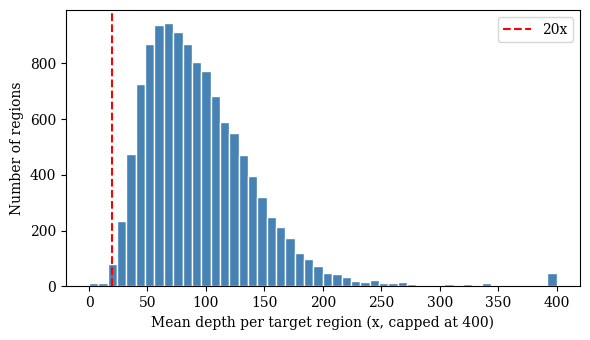

Regions below 20x: 48 of 11933


In [ ]:
# Coverage thresholds
thr = pd.read_csv(proj + '/alignment/sample.thresholds.bed.gz', sep='\t')
size = (thr['end'] - thr['start']).sum()
print("Target size on chr17:", size, "bp")

for t in ['10X', '20X', '30X']:
    pct = thr[t].sum() / size * 100
    print("Bases covered >=", t, ":", round(pct, 1), "%")

# Depth per region
reg = pd.read_csv(proj + '/alignment/sample.regions.bed.gz', sep='\t', header=None,
                  names=['chr', 'start', 'end', 'depth'])

# Figure setup (used by all later figure cells)
fig_dir = proj + '/results/figures/'
os.makedirs(fig_dir, exist_ok=True)
plt.rcParams.update({'font.family': 'serif', 'font.size': 10})

# Figure 2
plt.figure(figsize=(6, 3.5))
plt.hist(reg['depth'].clip(upper=400), bins=50, color='steelblue', edgecolor='white')
plt.axvline(20, color='red', linestyle='--', label='20x')
plt.xlabel('Mean depth per target region (x, capped at 400)')
plt.ylabel('Number of regions')
plt.legend()
plt.tight_layout()
plt.savefig(fig_dir + 'fig2_coverage.png', dpi=300)
plt.show()

low = (reg['depth'] < 20).sum()
print("Regions below 20x:", low, "of", len(reg))

## 8. Variant calling
GATK HaplotypeCaller finds SNVs and small indels in the capture regions (plus 100 bp of padding).
*Result: 4,711 raw variants.*

In [ ]:
%%bash
cd $PROJ
gatk HaplotypeCaller \
    -R reference/${CHR}.fa \
    -I alignment/sample.final.bam \
    -L reference/targets.bed -ip 100 \
    -O variants/sample.raw.vcf.gz 2>&1 | tail -1

echo
echo "Raw variants called: $(bcftools view -H variants/sample.raw.vcf.gz | wc -l)"

Runtime.totalMemory()=736100352

Raw variants called: 4711


In [ ]:
vcf = proj + '/variants/sample.raw.vcf.gz'

print("--- Header lines (INFO/FORMAT definitions) ---")
!bcftools view -h {vcf} | grep -E '^##(INFO|FORMAT)=<ID=(QD|FS|MQ|DP|GT|AD|GQ),'

print("\n--- First 5 variants ---")
!bcftools query -f '%CHROM\t%POS\t%REF\t%ALT\t%QUAL\t[%GT\t%AD\t%DP]\n' {vcf} | head -5

--- Header lines (INFO/FORMAT definitions) ---
##FORMAT=<ID=AD,Number=R,Type=Integer,Description="Allelic depths for the ref and alt alleles in the order listed">
##FORMAT=<ID=DP,Number=1,Type=Integer,Description="Approximate read depth (reads with MQ=255 or with bad mates are filtered)">
##FORMAT=<ID=GQ,Number=1,Type=Integer,Description="Genotype Quality">
##FORMAT=<ID=GT,Number=1,Type=String,Description="Genotype">
##INFO=<ID=DP,Number=1,Type=Integer,Description="Approximate read depth; some reads may have been filtered">
##INFO=<ID=FS,Number=1,Type=Float,Description="Phred-scaled p-value using Fisher's exact test to detect strand bias">
##INFO=<ID=MQ,Number=1,Type=Float,Description="RMS Mapping Quality">
##INFO=<ID=QD,Number=1,Type=Float,Description="Variant Confidence/Quality by Depth">

--- First 5 variants ---
chr17	156324	G	C	1816.64	0/1	67,69	136
chr17	156366	A	G	1883.64	0/1	61,65	126
chr17	162039	A	G	741.64	0/1	17,27	44
chr17	164114	G	A	803.64	0/1	44,31	75
chr17	164217	G	C	597

## 9. Variant filtering and summary statistics
Hard filters on quality, strand bias, mapping quality and read position remove likely false positives, with separate thresholds for SNVs and indels.
*Result: 4,381 PASS variants (3,790 SNVs, 591 indels); Ti/Tv 2.66.*

*Note: four mixed multiallelic sites (SNV plus indel, genotype 1/2) were not in the SNV or indel files and were not carried through filtering (4,060 + 647 + 4 = 4,711).*



In [ ]:
%%bash
cd $PROJ/variants
R=../reference/${CHR}.fa

gatk SelectVariants -R $R -V sample.raw.vcf.gz --select-type-to-include SNP   -O snps.vcf.gz   2>&1 | tail -1
gatk SelectVariants -R $R -V sample.raw.vcf.gz --select-type-to-include INDEL -O indels.vcf.gz 2>&1 | tail -1
echo "SNVs:   $(bcftools view -H snps.vcf.gz   | wc -l)"
echo "Indels: $(bcftools view -H indels.vcf.gz | wc -l)"

Runtime.totalMemory()=140509184
Runtime.totalMemory()=119537664
SNVs:   4060
Indels: 647


In [ ]:
%%bash
cd $PROJ/variants

bcftools isec -C -w1 sample.raw.vcf.gz snps.vcf.gz indels.vcf.gz \
    -Oz -o missing_variants.vcf.gz

bcftools index -t missing_variants.vcf.gz

echo "Missing variant records:"
bcftools view -H missing_variants.vcf.gz

Missing variant records:
chr17	738096	.	C	T,CTTTTTTTT	1084.04	.	AC=1,1;AF=0.5,0.5;AN=2;DP=38;ExcessHet=0;FS=0;MLEAC=1,1;MLEAF=0.5,0.5;MQ=60;QD=25.36;SOR=3.528	GT:AD:DP:GQ:PL	1/2:0,22,6:28:99:1101,172,447,885,0,868
chr17	7107768	.	T	*,TACACATTACACACACCGC	1504.01	.	AC=1,1;AF=0.5,0.5;AN=2;DP=70;ExcessHet=0;FS=0;MLEAC=1,1;MLEAF=0.5,0.5;MQ=60;QD=22.79;SOR=2.303	GT:AD:DP:GQ:PL	1/2:0,28,38:66:99:2645,1514,1547,1148,0,1056
chr17	73350214	.	A	C,ACCCGGGCACTGCTGGGCCTGGCCCCCC	3820.06	.	AC=1,1;AF=0.5,0.5;AN=2;DP=121;ExcessHet=0;FS=0;MLEAC=1,1;MLEAF=0.5,0.5;MQ=59.99;QD=27.84;SOR=1.916	GT:AD:DP:GQ:PL	1/2:0,51,39:90:99:3837,1588,1346,1641,0,1988
chr17	75212110	.	G	T,GTGTGTGTGTT	1093.06	.	AC=1,1;AF=0.5,0.5;AN=2;DP=41;ExcessHet=0;FS=0;MLEAC=1,1;MLEAF=0.5,0.5;MQ=60;QD=30.36;SOR=1.22	GT:AD:DP:GQ:PL	1/2:0,19,17:36:99:1110,570,562,562,0,744


In [ ]:
%%bash
cd $PROJ/variants
R=../reference/${CHR}.fa

gatk VariantFiltration -R $R -V snps.vcf.gz -O snps.filt.vcf.gz \
    --filter-name "QD2"  --filter-expression "QD < 2.0" \
    --filter-name "FS60" --filter-expression "FS > 60.0" \
    --filter-name "SOR3" --filter-expression "SOR > 3.0" \
    --filter-name "MQ40" --filter-expression "MQ < 40.0" \
    --filter-name "MQRS-12.5" --filter-expression "MQRankSum < -12.5" \
    --filter-name "RPRS-8" --filter-expression "ReadPosRankSum < -8.0" 2>&1 | tail -1

gatk VariantFiltration -R $R -V indels.vcf.gz -O indels.filt.vcf.gz \
    --filter-name "QD2"   --filter-expression "QD < 2.0" \
    --filter-name "FS200" --filter-expression "FS > 200.0" \
    --filter-name "SOR10" --filter-expression "SOR > 10.0" \
    --filter-name "RPRS-20" --filter-expression "ReadPosRankSum < -20.0" 2>&1 | tail -1

# Merge SNVs + indels back into one file and keep only PASS
bcftools concat -a snps.filt.vcf.gz indels.filt.vcf.gz -Oz -o sample.filtered.vcf.gz
bcftools index -t -f sample.filtered.vcf.gz
bcftools view -f PASS sample.filtered.vcf.gz -Oz -o sample.pass.vcf.gz
bcftools index -t -f sample.pass.vcf.gz

echo "Before filtering: $(bcftools view -H sample.raw.vcf.gz  | wc -l)"
echo "PASS variants:    $(bcftools view -H sample.pass.vcf.gz | wc -l)"
echo
echo "Which filters removed variants:"
bcftools query -f '%FILTER\n' sample.filtered.vcf.gz | sort | uniq -c


Runtime.totalMemory()=314572800
Runtime.totalMemory()=119537664
Before filtering: 4711
PASS variants:    4381

Which filters removed variants:
      2 FS60
      1 FS60;QD2;SOR3
     61 MQ40
      4 MQ40;QD2
     26 MQ40;SOR3
     33 MQRS-12.5
      2 MQRS-12.5;RPRS-8
   4381 PASS
     74 QD2
      1 RPRS-8
    122 SOR3


Checking the headers and starting positions of 2 files


In [29]:
%%bash
cd $PROJ/variants
bcftools stats sample.pass.vcf.gz > sample.pass.stats.txt
echo "--- Summary numbers ---"
grep '^SN' sample.pass.stats.txt | cut -f3-
echo
echo "--- Ti/Tv (SNVs) ---"
grep '^TSTV' sample.pass.stats.txt | cut -f3-5

--- Summary numbers ---
number of samples:	1
number of records:	4381
number of no-ALTs:	0
number of SNPs:	3790
number of MNPs:	0
number of indels:	591
number of others:	0
number of multiallelic sites:	53
number of multiallelic SNP sites:	0

--- Ti/Tv (SNVs) ---
2754	1036	2.66


PASS variants: 4381


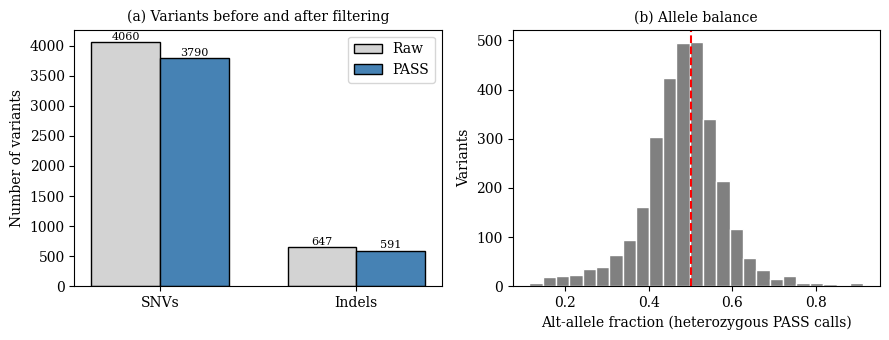

In [30]:
q = "%CHROM\\t%POS\\t%REF\\t%ALT\\t%QUAL\\t[%GT]\\t[%AD]\\t[%DP]\\n"
vc = pd.read_csv(os.popen(f"bcftools query -f '{q}' {proj}/variants/sample.pass.vcf.gz"),
                 sep='\t', header=None, names=['chrom','pos','ref','alt','qual','gt','ad','dp'])
print(f"PASS variants: {len(vc)}")

# Allele balance of heterozygous calls (should centre near 0.5)
het = vc[vc['gt'].isin(['0/1', '0|1'])].copy()
het['alt_frac'] = het['ad'].apply(lambda s: int(s.split(',')[1]) / max(1, sum(int(x) for x in s.split(','))))

# Figure 3
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
raw = [4060, 647]; pas = [3790, 591]            # values from Table 7
x = np.arange(2); w = 0.35
ax[0].bar(x - w/2, raw, w, label='Raw', color='lightgrey', edgecolor='black')
ax[0].bar(x + w/2, pas, w, label='PASS', color='steelblue', edgecolor='black')
for i, (r, p) in enumerate(zip(raw, pas)):
    ax[0].text(i - w/2, r + 40, r, ha='center', fontsize=8)
    ax[0].text(i + w/2, p + 40, p, ha='center', fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels(['SNVs', 'Indels'])
ax[0].set_ylabel('Number of variants'); ax[0].legend()
ax[0].set_title('(a) Variants before and after filtering', fontsize=10)
ax[1].hist(het.alt_frac, bins=25, color='grey', edgecolor='white')
ax[1].axvline(0.5, color='red', ls='--')
ax[1].set_xlabel('Alt-allele fraction (heterozygous PASS calls)'); ax[1].set_ylabel('Variants')
ax[1].set_title('(b) Allele balance', fontsize=10)
plt.tight_layout()
plt.savefig(fig_dir + 'fig3_variants.png', dpi=300)
plt.show()

In [31]:
# SNV or indel
def variant_type(row):
    if len(row['ref']) == 1 and len(row['alt']) == 1:
        return 'SNV'
    return 'indel'

# het or hom-alt
def zygosity(gt):
    if gt in ['0/1', '0|1']:
        return 'het'
    if gt in ['1/1', '1|1']:
        return 'hom-alt'
    return 'other'

vc['type'] = vc.apply(variant_type, axis=1)
vc['zygosity'] = vc['gt'].apply(zygosity)
display(pd.crosstab(vc['type'], vc['zygosity'], margins=True))

# Transitions vs transversions
transitions = {'AG', 'GA', 'CT', 'TC'}
snv = vc[vc['type'] == 'SNV']
changes = snv['ref'] + snv['alt']

ti = changes.isin(transitions).sum()
tv = len(snv) - ti
print("Transitions:", ti)
print("Transversions:", tv)
print("Ti/Tv:", round(ti / tv, 2))

zygosity,het,hom-alt,other,All
type,,,,
SNV,2628,1157,0,3785
indel,378,165,53,596
All,3006,1322,53,4381


Transitions: 2753
Transversions: 1032
Ti/Tv: 2.67


## 10. Variant annotation


### 10a. Population frequency (gnomAD)
Splits multiallelic sites and adds the gnomAD allele frequency, separating common variants from rare or novel ones.
*Result: 51 candidates (41 missense, 9 inframe indels, 1 frameshift); 9 sit in clusters and 4 have unusually high depth (>300x).*

In [32]:
%%bash
cd $PROJ/variants
bcftools norm -m-any -f ../reference/${CHR}.fa sample.pass.vcf.gz -Oz -o sample.norm.vcf.gz 2>/dev/null
bcftools index -t -f sample.norm.vcf.gz

echo '##INFO=<ID=gnomAD_AF,Number=A,Type=Float,Description="gnomAD allele frequency">' > gnomad_header.txt
bcftools annotate -a ../reference/gnomad.vcf.gz -c INFO/gnomAD_AF:=INFO/AF -h gnomad_header.txt \
    sample.norm.vcf.gz -Oz -o sample.annotated.vcf.gz
bcftools index -t -f sample.annotated.vcf.gz
echo "Annotated file: $(bcftools view -H sample.annotated.vcf.gz | wc -l) variants"

Annotated file: 4434 variants


In [33]:
cols = ['CHROM','POS','REF','ALT','QUAL','GT','AD','DP','GQ','gnomAD_AF']
q = "%CHROM\\t%POS\\t%REF\\t%ALT\\t%QUAL\\t[%GT]\\t[%AD]\\t[%DP]\\t[%GQ]\\t%INFO/gnomAD_AF\\n"
df = pd.read_csv(os.popen(f"bcftools query -f '{q}' {proj}/variants/sample.annotated.vcf.gz"),
                 sep='\t', header=None, names=cols, na_values=['.'])
df['gnomAD_AF'] = pd.to_numeric(df['gnomAD_AF'], errors='coerce')

known = df.gnomAD_AF.notna()
print(df.shape)
print(f"Variants already seen in gnomAD: {known.sum()} of {len(df)} ({known.mean()*100:.0f}%)")
display(df.head(10))

(4434, 10)
Variants already seen in gnomAD: 3994 of 4434 (90%)


,CHROM,POS,REF,ALT,QUAL,GT,AD,DP,GQ,gnomAD_AF
0,chr17,156324,G,C,1816.64,0/1,"67,69",136,99,0.717
1,chr17,156366,A,G,1883.64,0/1,"61,65",126,99,0.726
2,chr17,162039,A,G,741.64,0/1,"17,27",44,99,0.836
3,chr17,164114,G,A,803.64,0/1,"44,31",75,99,0.754
4,chr17,164217,G,C,597.64,0/1,"29,21",50,99,0.824
5,chr17,215560,C,T,2498.06,1/1,"0,80",80,99,0.938
6,chr17,215841,C,T,894.64,0/1,"45,34",79,99,0.422
7,chr17,219577,G,C,327.64,0/1,"13,13",26,99,0.207
8,chr17,281725,C,A,283.64,0/1,"27,13",40,99,0.459
9,chr17,281918,A,G,851.64,0/1,"12,31",43,99,0.350


### 10b. Functional consequences (bcftools csq)
Predicts each variant's effect on Ensembl GRCh38 transcripts (missense, stop-gained, splice and so on), keeping the most severe effect per variant and ignoring NMD transcripts.
*Result: 609 missense, 6 stop-gained, 9 splice donor/acceptor, 4 start-lost and 1 frameshift variants.*

In [34]:
%%bash
cd $PROJ/reference
wget -q https://ftp.ensembl.org/pub/release-113/gff3/homo_sapiens/Homo_sapiens.GRCh38.113.chr.gff3.gz
ls -lh Homo_sapiens.GRCh38.113.chr.gff3.gz

zcat Homo_sapiens.GRCh38.113.chr.gff3.gz \
  | awk 'BEGIN{FS=OFS="\t"} /^#/{next} $1=="17"{$1="chr17"; print}' \
  | gzip > chr17.gff3.gz
zcat chr17.gff3.gz | head -3

-rw-r--r-- 1 root root 53M Aug 18  2024 Homo_sapiens.GRCh38.113.chr.gff3.gz
chr17	GRCh38	chromosome	1	83257441	.	.	.	ID=chromosome:17;Alias=CM000679.2,chr17,NC_000017.11
chr17	.	biological_region	61680	61746	0.995	-	.	external_name=rank %3D 1;logic_name=firstef
chr17	.	biological_region	62925	63732	0.917	-	.	external_name=rank %3D 1;logic_name=firstef


In [35]:
%%bash
cd $PROJ/variants
bcftools csq -f ../reference/chr17.fa -g ../reference/chr17.gff3.gz -p a --ncsq 50 \
    sample.annotated.vcf.gz -Oz -o sample.csq.vcf.gz 2>&1 | grep -v "unknown phase\|truncated transcript"
bcftools index -t -f sample.csq.vcf.gz

Parsing ../reference/chr17.gff3.gz ...
Indexed 19412 transcripts, 112344 exons, 55328 CDSs, 24325 UTRs
Ignored the following biotypes:
	104x	.. TEC
Calling...


In [36]:
import subprocess, io

rank = ['transcript_ablation','splice_acceptor','splice_donor','stop_gained','frameshift',
        'stop_lost','start_lost','inframe_insertion','inframe_deletion','missense',
        'splice_region','stop_retained','synonymous','5_prime_utr','3_prime_utr','intron','non_coding']

def worst(csq):
    if pd.isna(csq) or csq in ('.', ''):
        return pd.Series({'consequence': 'none', 'gene': None})
    best = (99, None, None)
    for e in csq.split(','):
        f = e.lstrip('*').split('|')
        if f[0].startswith('@') or len(f) < 2 or 'NMD_transcript' in f[0]:
            continue
        for t in f[0].split('&'):
            r = rank.index(t) if t in rank else 50
            if r < best[0]:
                best = (r, t, f[1])
    return pd.Series({'consequence': best[1] or 'NMD-only/other', 'gene': best[2]})

q = "%CHROM\t%POS\t%REF\t%ALT\t%INFO/BCSQ\n"
out = subprocess.run(['bcftools','query','-f',q, proj + '/variants/sample.csq.vcf.gz'],
                     capture_output=True, text=True).stdout
csq = pd.read_csv(io.StringIO(out), sep='\t', header=None,
                  names=['CHROM','POS','REF','ALT','BCSQ'], na_values=['.'])
csq[['consequence','gene']] = csq['BCSQ'].apply(worst)

annot = df.merge(csq[['CHROM','POS','REF','ALT','consequence','gene']],
                 on=['CHROM','POS','REF','ALT'], how='left')
print(annot.consequence.value_counts())

consequence
intron               2351
synonymous            656
missense              609
3_prime_utr           276
5_prime_utr           181
splice_region         148
NMD-only/other         67
non_coding             59
none                   40
inframe_deletion       15
inframe_insertion      12
stop_gained             6
splice_donor            5
start_lost              4
splice_acceptor         4
frameshift              1
Name: count, dtype: int64


## 11. Candidate variant selection
Keeps variants with sufficient depth and genotype quality (DP ≥ 10, GQ ≥ 20) that are rare or novel in gnomAD and change the protein, and flags variants lying in tight clusters.
*Result: 51 candidates (41 missense, 9 inframe indels, 1 frameshift); 9 sit in clusters. 4 candidates have unusually high depth (>300x)*

In [37]:
impact = ['stop_gained','splice_acceptor','splice_donor','frameshift','start_lost','stop_lost',
          'inframe_insertion','inframe_deletion','missense']

good = annot[(annot.DP >= 10) & (annot.GQ >= 20)].copy()
good['rarity'] = np.where(good.gnomAD_AF.isna(), 'not in gnomAD',
                  np.where(good.gnomAD_AF < 0.01, 'rare (<1%)', 'common'))

rare = good[good.rarity != 'common'].sort_values('POS')
gap = rare.POS.diff().abs()
rare['cluster'] = (gap < 200) | (gap.shift(-1) < 200)
good['cluster'] = False
good.loc[rare.index, 'cluster'] = rare['cluster']
good['high_depth'] = good.DP > 300      # more than ~2.5x the 117x mean: possible collapsed repeat

candidates = good[(good.rarity != 'common') & (good.consequence.isin(impact))] \
                 .sort_values('QUAL', ascending=False)

print(len(candidates), "candidates;", candidates.cluster.sum(), "clustered;",
      candidates.high_depth.sum(), "with unusually high depth")
display(candidates[['POS','REF','ALT','gene','consequence','GT','DP','gnomAD_AF','rarity','cluster','high_depth']].head(20))
display(candidates.consequence.value_counts())


51 candidates; 9 clustered; 4 with unusually high depth


,POS,REF,ALT,gene,consequence,GT,DP,gnomAD_AF,rarity,cluster,high_depth
3977,80090216,G,C,CCDC40,missense,1/1,343,NaN,not in gnomAD,True,True
2162,41149523,T,TGGCAGCAGCTGGGGC,KRTAP4-5,inframe_insertion,1/1,496,NaN,not in gnomAD,False,True
3978,80090265,G,A,CCDC40,missense,1/1,328,NaN,not in gnomAD,True,True
742,7513774,CCA,C,POLR2A,frameshift,1/1,152,NaN,not in gnomAD,False,False
638,7024700,C,CCAG,BCL6B,inframe_insertion,0/1,217,NaN,not in gnomAD,False,False
3555,74866471,T,C,FDXR,missense,1/1,159,NaN,not in gnomAD,False,False
15,413794,TGACCCCGAGGCCCTCAAGGGCTTCCACCCCGACCCCAAGGCCCTC...,T,LIAT1,inframe_deletion,0/1,186,NaN,not in gnomAD,False,False
14,413576,A,T,LIAT1,missense,0/1,498,NaN,not in gnomAD,True,True
13,413503,C,G,LIAT1,missense,1/1,170,NaN,not in gnomAD,True,False
3558,74866908,C,T,FDXR,missense,1/1,140,NaN,not in gnomAD,False,False


,count
consequence,
missense,41
inframe_insertion,6
inframe_deletion,3
frameshift,1


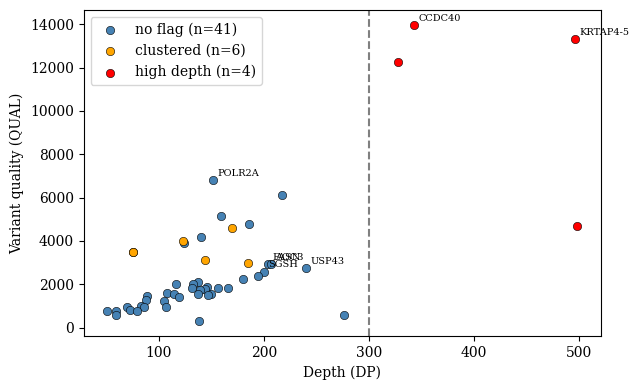

In [44]:
c = candidates.copy()
c['flag'] = np.where(c.high_depth, 'high depth', np.where(c.cluster, 'clustered', 'no flag'))
plt.figure(figsize=(6.5, 4))
for f, col in {'no flag': 'steelblue', 'clustered': 'orange', 'high depth': 'red'}.items():
    s = c[c.flag == f]
    plt.scatter(s.DP, s.QUAL, c=col, label=f'{f} (n={len(s)})', edgecolor='black', linewidth=0.4)
plt.axvline(300, color='grey', ls='--')
for g in ['FASN', 'USP43', 'AOC3', 'SGSH', 'CCDC40', 'KRTAP4-5', 'POLR2A']:
    for _, r in c[c.gene == g].head(1).iterrows():
        plt.annotate(g, (r.DP, r.QUAL), fontsize=7, xytext=(3, 3), textcoords='offset points')
plt.xlabel('Depth (DP)'); plt.ylabel('Variant quality (QUAL)'); plt.legend()
plt.tight_layout()
plt.savefig(fig_dir + 'fig6_candidates.png', dpi=300)
plt.show()

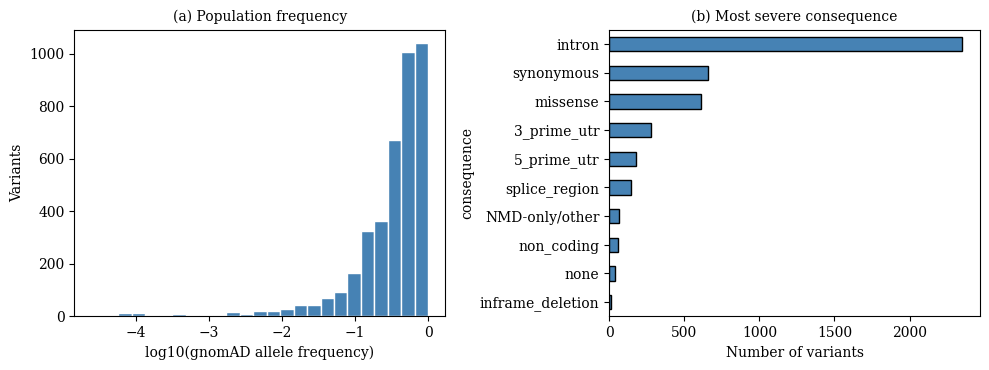

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
known_af = good.gnomAD_AF.dropna()
ax[0].hist(np.log10(known_af[known_af > 0]), bins=25, color='steelblue', edgecolor='white')
ax[0].set_xlabel('log10(gnomAD allele frequency)'); ax[0].set_ylabel('Variants')
ax[0].set_title('(a) Population frequency', fontsize=10)
annot.consequence.value_counts().head(10).iloc[::-1].plot.barh(ax=ax[1], color='steelblue', edgecolor='black')
ax[1].set_xlabel('Number of variants'); ax[1].set_title('(b) Most severe consequence', fontsize=10)
plt.tight_layout()
plt.savefig(fig_dir + 'fig5_annotation.png', dpi=300)
plt.show()

## 12. Accuracy benchmark against the GIAB truth set
Compares the calls with the GIAB truth set inside regions that are both captured and high-confidence. Precision shows how many calls are real; recall shows how many true variants were found.
*Result (PASS calls): SNVs precision 0.989, recall 0.976; indels precision 0.833, recall 1.000 (only 35 true-positive indels).*

In [41]:
%%bash
cd $PROJ
R=reference
# regions where we can grade: captured AND GIAB-confident
bedtools intersect -a $R/targets.bed -b $R/giab_confident.bed | sort -k2,2n | bedtools merge > $R/eval_regions.bed

# normalise the truth the same way as our calls
bcftools norm -m-any -f $R/${CHR}.fa $R/truth.vcf.gz -Oz -o $R/truth.norm.vcf.gz 2>/dev/null
bcftools index -t -f $R/truth.norm.vcf.gz

compare () {   # $1 = our VCF, $2 = output folder
    rm -rf $2
    bcftools isec -R $R/eval_regions.bed -p $2 $R/truth.norm.vcf.gz $1
}
# raw calls (before filtering) and PASS calls (after filtering)
bcftools norm -m-any -f $R/${CHR}.fa variants/sample.raw.vcf.gz -Oz -o variants/sample.raw.norm.vcf.gz 2>/dev/null
bcftools index -t -f variants/sample.raw.norm.vcf.gz
compare variants/sample.raw.norm.vcf.gz  results/compare_raw
compare variants/sample.norm.vcf.gz      results/compare_pass
echo "Done: 0000.vcf = only truth (FN), 0001.vcf = only ours (FP), 0002.vcf = in both (TP)"

Done: 0000.vcf = only truth (FN), 0001.vcf = only ours (FP), 0002.vcf = in both (TP)


In [42]:
def n_variants(path, vtype):
    flag = '-v snps' if vtype == 'SNV' else '-V snps'
    return int(os.popen(f"bcftools view -H {flag} {path} | wc -l").read())

rows = []
for label in ['raw', 'pass']:
    d = f"{proj}/results/compare_{label}"
    for vtype in ['SNV', 'indel']:
        fn = n_variants(f"{d}/0000.vcf", vtype)
        fp = n_variants(f"{d}/0001.vcf", vtype)
        tp = n_variants(f"{d}/0002.vcf", vtype)
        rows.append({'callset': label, 'type': vtype, 'TP': tp, 'FP': fp, 'FN': fn,
                     'precision': tp / max(1, tp + fp), 'recall': tp / max(1, tp + fn)})
bench = pd.DataFrame(rows)
display(bench.style.format({'precision': '{:.3f}', 'recall': '{:.3f}'}))

,callset,type,TP,FP,FN,precision,recall
0,raw,SNV,1460,42,15,0.972,0.990
1,raw,indel,35,13,0,0.729,1.000
2,pass,SNV,1439,16,36,0.989,0.976
3,pass,indel,35,7,0,0.833,1.000


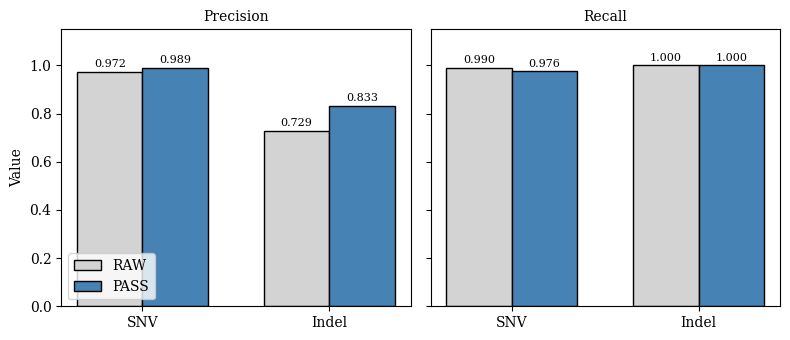

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)
for a, metric in zip(ax, ['precision', 'recall']):
    for k, (cs, col) in enumerate([('raw', 'lightgrey'), ('pass', 'steelblue')]):
        vals = [bench[(bench.callset == cs) & (bench.type == t)][metric].values[0] for t in ['SNV', 'indel']]
        a.bar(np.arange(2) + (k - 0.5) * 0.35, vals, 0.35, label=cs.upper(), color=col, edgecolor='black')
        for i, v in enumerate(vals):
            a.text(i + (k - 0.5) * 0.35, v + 0.02, f'{v:.3f}', ha='center', fontsize=8)
    a.set_xticks([0, 1]); a.set_xticklabels(['SNV', 'Indel'])
    a.set_ylim(0, 1.15); a.set_title(metric.capitalize(), fontsize=10)
ax[0].legend(loc='lower left'); ax[0].set_ylabel('Value')
plt.tight_layout()
plt.savefig(fig_dir + 'fig4_benchmark.png', dpi=300)
plt.show()

## 13. Save results and software versions
Writes the variant tables, benchmark and QC summary to `results/` and records tool versions for reproducibility.

In [45]:
annot.to_csv(proj + '/results/variants_all.csv', index=False)
candidates.to_csv(proj + '/results/variants_candidates.csv', index=False)
bench.to_csv(proj + '/results/benchmark_vs_giab.csv', index=False)

qc = pd.DataFrame({
    'metric': ['read_pairs_raw', 'reads_after_trim', 'variants_raw', 'variants_PASS', 'candidates'],
    'value':  [n1, after['total_reads'] // 2,
               int(os.popen(f"bcftools view -H {proj}/variants/sample.raw.vcf.gz | wc -l").read()),
               len(good), len(candidates)],
})
qc.to_csv(proj + '/results/qc_summary.csv', index=False)
display(qc)

,metric,value
0,read_pairs_raw,2387574
1,reads_after_trim,2367112
2,variants_raw,4711
3,variants_PASS,4381
4,candidates,51


In [46]:
%%bash
cd $PROJ
{
echo "Date: $(date)"
echo "Sample: HG003 (GIAB)   Region: $CHR   Reference: GRCh38"
echo "bwa:      $(bwa 2>&1 | grep -i '^Version')"
echo "samtools: $(samtools --version | head -1)"
echo "bcftools: $(bcftools --version | head -1)"
echo "gatk:     $(gatk --version 2>/dev/null | grep 'Genome Analysis Toolkit')"
echo "mosdepth: $(mosdepth --version)"
} > results/software_versions.txt
cat results/software_versions.txt
echo; ls -lh results/

Date: Wed Nov 11 07:34:11 AM UTC 2026
Sample: HG003 (GIAB)   Region: chr17   Reference: GRCh38
bwa:      Version: 0.7.19-r1273
samtools: samtools 1.25
bcftools: bcftools 1.25
gatk:     The Genome Analysis Toolkit (GATK) v4.6.2.0
mosdepth: mosdepth 0.3.3

total 320K
-rw-r--r-- 1 root root  236 Nov 11 07:34 benchmark_vs_giab.csv
drwxr-xr-x 2 root root 4.0K Nov 11 07:30 compare_pass
drwxr-xr-x 2 root root 4.0K Nov 11 07:30 compare_raw
drwxr-xr-x 2 root root 4.0K Nov 11 07:32 figures
-rw-r--r-- 1 root root  112 Nov 11 07:34 qc_summary.csv
-rw-r--r-- 1 root root  254 Nov 11 07:34 software_versions.txt
-rw-r--r-- 1 root root 287K Nov 11 07:34 variants_all.csv
-rw-r--r-- 1 root root 4.8K Nov 11 07:34 variants_candidates.csv


In [47]:
%%bash
ls -lh $PROJ/results/figures

total 584K
-rw-r--r-- 1 root root  69K Nov 11 07:12 fig2_coverage.png
-rw-r--r-- 1 root root 137K Nov 11 07:26 fig3_variants.png
-rw-r--r-- 1 root root  71K Nov 11 07:30 fig4_benchmark.png
-rw-r--r-- 1 root root 154K Nov 11 07:28 fig5_annotation.png
-rw-r--r-- 1 root root 141K Nov 11 07:32 fig6_candidates.png


In [48]:
import shutil, os
from google.colab import files

exp = proj + '/export'
shutil.rmtree(exp, ignore_errors=True)
os.makedirs(exp + '/qc')
shutil.copytree(proj + '/results', exp + '/results')
for f in ['multiqc_report.html', 'fastp.html']:
    shutil.copy(proj + '/qc/' + f, exp + '/qc/' + f)

shutil.make_archive(proj + '/exome_chr17_files', 'zip', exp)
print("Files in the zip:")
for root, d, fs in os.walk(exp):
    for f in fs:
        print(" ", os.path.relpath(os.path.join(root, f), exp))
files.download(proj + '/exome_chr17_files.zip')

Files in the zip:
  qc/fastp.html
  qc/multiqc_report.html
  results/variants_all.csv
  results/variants_candidates.csv
  results/qc_summary.csv
  results/benchmark_vs_giab.csv
  results/software_versions.txt
  results/compare_pass/0001.vcf
  results/compare_pass/0002.vcf
  results/compare_pass/README.txt
  results/compare_pass/0003.vcf
  results/compare_pass/sites.txt
  results/compare_pass/0000.vcf
  results/compare_raw/0001.vcf
  results/compare_raw/0002.vcf
  results/compare_raw/README.txt
  results/compare_raw/0003.vcf
  results/compare_raw/sites.txt
  results/compare_raw/0000.vcf
  results/figures/fig5_annotation.png
  results/figures/fig2_coverage.png
  results/figures/fig3_variants.png
  results/figures/fig4_benchmark.png
  results/figures/fig6_candidates.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limitations
- **Single sample, one chromosome.** This is HG003, a public reference individual, restricted to chr17. The findings are a pipeline demonstration, not clinical interpretation.
- **Hard filters.** With one sample, variant filtering uses fixed thresholds rather than a trained model (VQSR), so some false positives and false negatives remain.
- **Indels in repeat regions are less reliable.** Candidates such as those in repeat-rich genes should be checked visually (for example in IGV) before being trusted.
- **"Not in gnomAD" can be overstated for indels.** The same indel can be written in different ways, so a common variant may appear novel.
- **Clustered candidates** (several rare variants within 200 bp) are flagged because they are often mapping or repeat artifacts.
- **Consequences come from `bcftools csq`**, which covers coding and splice effects and does not give SnpEff-style impact categories (HIGH/MODERATE/LOW).
- **Benchmark scope.** Accuracy is measured only in captured, GIAB-confident regions, and the indel estimate rests on few calls.